In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("data/traffic_accident_dataset.csv")

In [3]:
df.shape

(8400, 26)

In [4]:
df.columns

Index(['accident_id', 'date', 'time', 'day_of_week', 'hour', 'state',
       'road_type', 'junction_type', 'weather_condition', 'road_condition',
       'light_condition', 'speed_kmh', 'speed_limit_kmh', 'visibility_m',
       'num_vehicles', 'driver_age', 'driver_experience_yrs', 'vehicle_type',
       'alcohol_involved', 'seatbelt_worn', 'num_casualties',
       'redundant_record_id', 'system_flag', 'random_noise_code',
       'useless_ratio', 'accident_severity'],
      dtype='str')

In [5]:
df.head()

,accident_id,date,time,day_of_week,hour,state,road_type,junction_type,weather_condition,road_condition,...,driver_experience_yrs,vehicle_type,alcohol_involved,seatbelt_worn,num_casualties,redundant_record_id,system_flag,random_noise_code,useless_ratio,accident_severity
0,ACC06301,2022-09-21,00:00,Wednesday,0,Tx,Highway,T-Junction,Rainy,Dry,...,5.7,Bus,1.0,NaN,0,6301,PROCESSED,491179,0.4307,Minor
1,ACC00568,2022-08-04,16:00,Saturday,16,ny,Expressway,NaN,Snowy,Dry,...,6.1,SUV,0.0,1.0,4,568,PROCESSED,536127,0.7789,Severe
2,ACC06208,2020-01-28,10:00,Thursday,10,CA,Urban Road,T-Junction,Rainy,Dry,...,18.8,SUV,NaN,0.0,3,6208,PROCESSED,941209,0.8207,Severe
3,ACC01115,2020-01-20,19:00,Thursday,19,Ill.,Urban Road,T-Junction,Clear,Wet,...,13.1,Motorcycle,0.0,NaN,0,1115,PROCESSED,307852,0.1462,Moderate
4,ACC03379,2021-03-27,07:00,Wednesday,7,WA,Urban Road,Crossroads,Clear,Wet,...,15.1,Car,NaN,1.0,0,3379,PROCESSED,282888,0.7971,Minor


In [6]:
df.tail()

,accident_id,date,time,day_of_week,hour,state,road_type,junction_type,weather_condition,road_condition,...,driver_experience_yrs,vehicle_type,alcohol_involved,seatbelt_worn,num_casualties,redundant_record_id,system_flag,random_noise_code,useless_ratio,accident_severity
8395,ACC05189,2023-06-29,16:00,Monday,16,OH,Urban Road,NaN,Clear,NaN,...,16.2,Truck,1.0,0.0,3,5189,PROCESSED,506786,0.3441,Severe
8396,ACC07891,2020-11-10,13:00,Monday,13,OH,Urban Road,Roundabout,Clear,Dry,...,16.4,Van,0.0,1.0,1,7891,PROCESSED,651262,0.3867,Moderate
8397,ACC01769,2021-06-17,05:00,Tuesday,5,Texas,One-way,Roundabout,Wet Weather,Wet,...,7.2,NaN,0.0,NaN,0,1769,PROCESSED,176908,0.8300,Moderate
8398,ACC03241,2020-08-18,06:00,Thursday,6,WA,Highway,Crossroads,Foggy,Dry,...,12.0,Motorcycle,1.0,0.0,0,3241,PROCESSED,254324,0.8566,Moderate
8399,ACC07204,2023-02-05,14:00,Friday,14,WA,Urban Road,NaN,Windy,Wet,...,14.4,Bus,NaN,0.0,3,7204,PROCESSED,795623,0.6855,Severe


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8400 entries, 0 to 8399
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   accident_id            8400 non-null   str    
 1   date                   8400 non-null   str    
 2   time                   8400 non-null   str    
 3   day_of_week            8400 non-null   str    
 4   hour                   8400 non-null   int64  
 5   state                  8400 non-null   str    
 6   road_type              8400 non-null   str    
 7   junction_type          5952 non-null   str    
 8   weather_condition      7542 non-null   str    
 9   road_condition         7548 non-null   str    
 10  light_condition        7603 non-null   str    
 11  speed_kmh              7563 non-null   float64
 12  speed_limit_kmh        8400 non-null   int64  
 13  visibility_m           7542 non-null   float64
 14  num_vehicles           8400 non-null   int64  
 15  driver_age     

In [8]:
df.duplicated().sum()


np.int64(400)

In [9]:
df=df.drop_duplicates().reset_index(drop=True)

In [10]:
df.shape

(8000, 26)

In [11]:
df.isna().sum()

accident_id                 0
date                        0
time                        0
day_of_week                 0
hour                        0
state                       0
road_type                   0
junction_type            2350
weather_condition         819
road_condition            824
light_condition           754
speed_kmh                 805
speed_limit_kmh             0
visibility_m              812
num_vehicles                0
driver_age                811
driver_experience_yrs     757
vehicle_type              811
alcohol_involved          801
seatbelt_worn             809
num_casualties              0
redundant_record_id         0
system_flag                 0
random_noise_code           0
useless_ratio               0
accident_severity           0
dtype: int64

In [12]:
df.dtypes

accident_id                  str
date                         str
time                         str
day_of_week                  str
hour                       int64
state                        str
road_type                    str
junction_type                str
weather_condition            str
road_condition               str
light_condition              str
speed_kmh                float64
speed_limit_kmh            int64
visibility_m             float64
num_vehicles               int64
driver_age               float64
driver_experience_yrs    float64
vehicle_type                 str
alcohol_involved         float64
seatbelt_worn            float64
num_casualties             int64
redundant_record_id        int64
system_flag                  str
random_noise_code          int64
useless_ratio            float64
accident_severity            str
dtype: object

In [13]:
df['accident_severity'].value_counts()

accident_severity
Minor       2667
Severe      2667
Moderate    2666
Name: count, dtype: int64

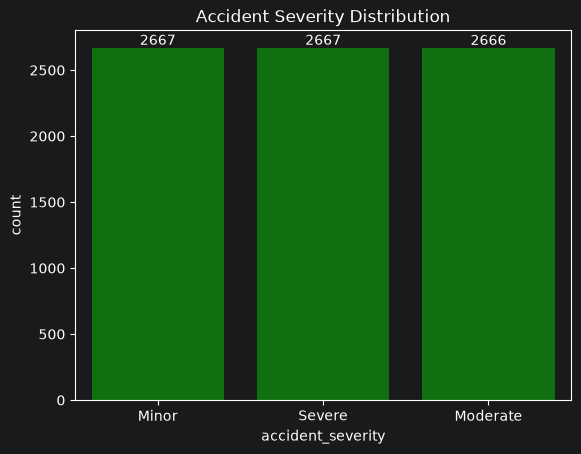

In [14]:
sns.countplot(x=df['accident_severity'],data=df,color='g')
plt.title('Accident Severity Distribution')
for container in plt.gca().containers:
    plt.bar_label(container)

Text(0.5, 1.0, 'Day of Week Distribution')

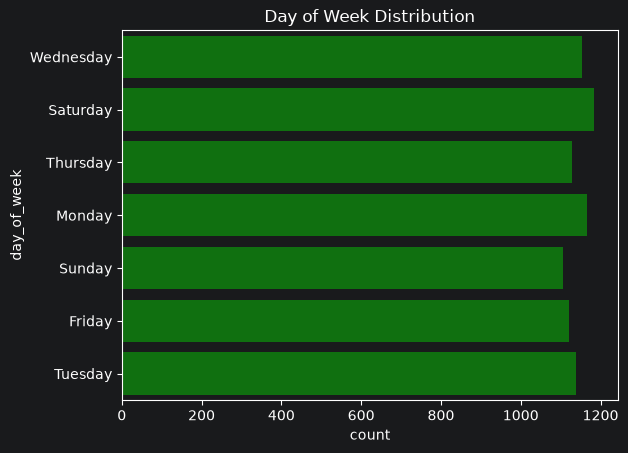

In [15]:
sns.countplot(y=df['day_of_week'],data=df,color='g')
plt.title('Day of Week Distribution')

Text(0.5, 1.0, 'Distribution of Road Types')

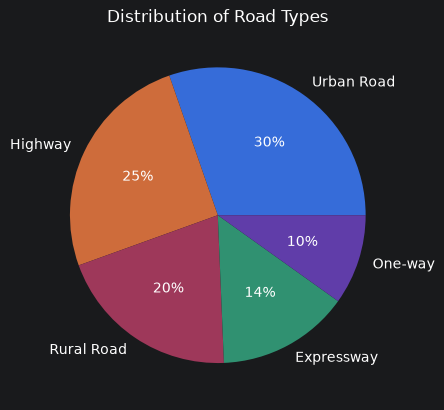

In [16]:
count=df['road_type'].value_counts()
plt.pie(count.values,labels=count.index,autopct='%1.f%%')
plt.title('Distribution of Road Types')


In [17]:
df['weather_condition'].unique()

<ArrowStringArray>
[       'Rainy',        'Snowy',        'Clear',        'Windy',
        'Foggy',        'Storm',        'foggy',            nan,
        'clear',         'Snow',       'Stormy',        'windy',
    'High Wind',  'Wet Weather',      'Raining', 'Thunderstorm',
         'Fair',        'snowy',          'Fog',        'CLEAR',
        'Sunny',        'Misty',    'Snow Fall',        'rainy',
         'Rain']
Length: 25, dtype: str

In [18]:
weather_map={
    'Rainy':'Rain','Wet Weather':'Rain','Raining':'Rain','rainy':'Rain','Rain':'Rain',
    'Snowy':'Snow','Snow':'Snow','snowy':'Snow','Snow Fall':'Snow',
    'Clear':'Clear','clear':'Clear','Fair':'Clear','CLEAR':'Clear','Sunny':'Clear',
    'Windy':'Wind','windy':'Wind','High Wind':'Wind',
    'Foggy':'Fog','foggy':'Fog','Fog':'Fog','Misty':'Fog',
    'Storm':'Storm','Stormy':'Storm','Thunderstorm':'Storm'
}

In [19]:
df['weather_condition']=df['weather_condition'].map(weather_map)

Text(0.5, 1.0, 'Weather Condition Distribution')

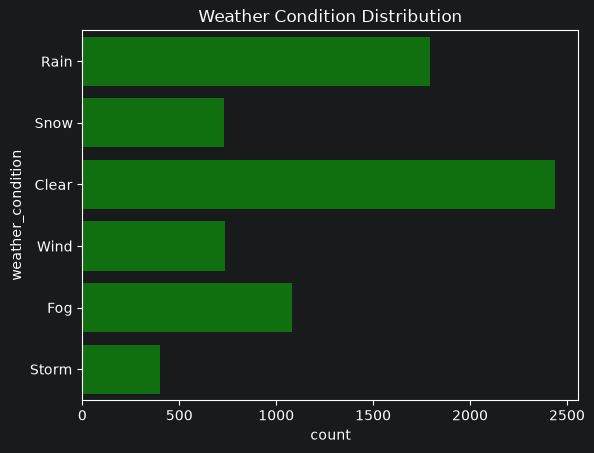

In [20]:
sns.countplot(y=df['weather_condition'],color='g')
plt.title('Weather Condition Distribution')

Text(0.5, 1.0, 'Road Condition Distribution')

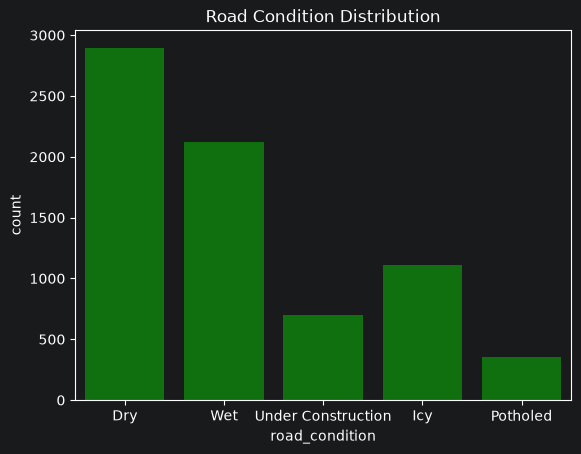

In [21]:
sns.countplot(x=df['road_condition'],color='g')
plt.title('Road Condition Distribution')

Text(0.5, 1.0, 'Distribution of Light Condition')

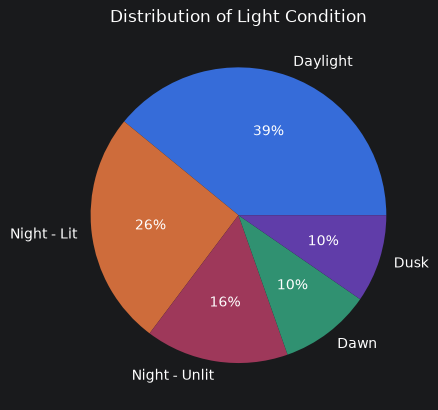

In [22]:
count=df['light_condition'].value_counts()
plt.pie(count.values,labels=count.index,autopct='%1.f%%')
plt.title('Distribution of Light Condition')

Text(0.5, 1.0, 'Vehicle Type Distribution')

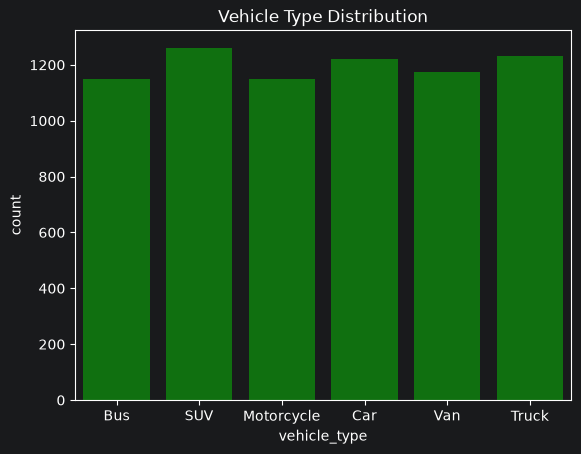

In [23]:
sns.countplot(x=df['vehicle_type'],color='g')
plt.title('Vehicle Type Distribution')

In [24]:
df.dtypes

accident_id                  str
date                         str
time                         str
day_of_week                  str
hour                       int64
state                        str
road_type                    str
junction_type                str
weather_condition            str
road_condition               str
light_condition              str
speed_kmh                float64
speed_limit_kmh            int64
visibility_m             float64
num_vehicles               int64
driver_age               float64
driver_experience_yrs    float64
vehicle_type                 str
alcohol_involved         float64
seatbelt_worn            float64
num_casualties             int64
redundant_record_id        int64
system_flag                  str
random_noise_code          int64
useless_ratio            float64
accident_severity            str
dtype: object

Text(0.5, 1.0, 'speed_kmh')

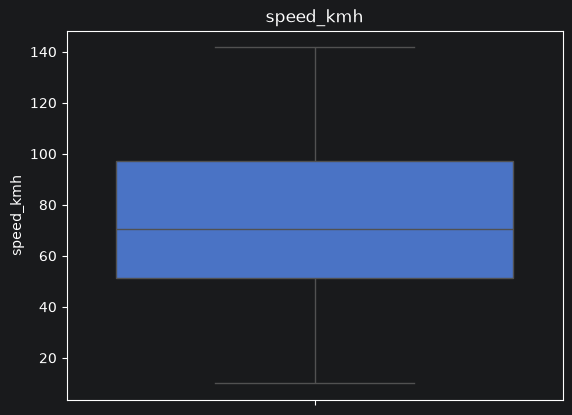

In [25]:
sns.boxplot(y=df['speed_kmh'])
plt.title('speed_kmh')

Text(0.5, 1.0, 'visibility_m')

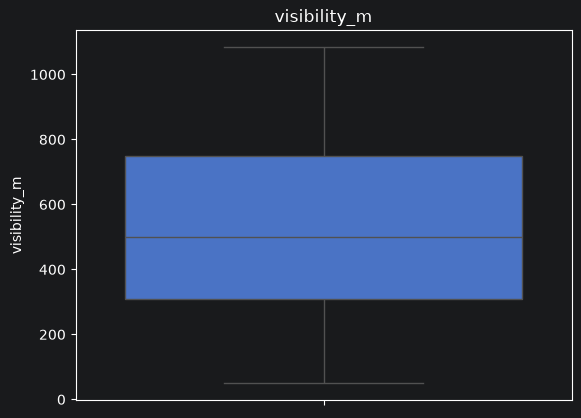

In [26]:

sns.boxplot(y=df['visibility_m'])
plt.title('visibility_m')

Text(0.5, 1.0, 'driver_age')

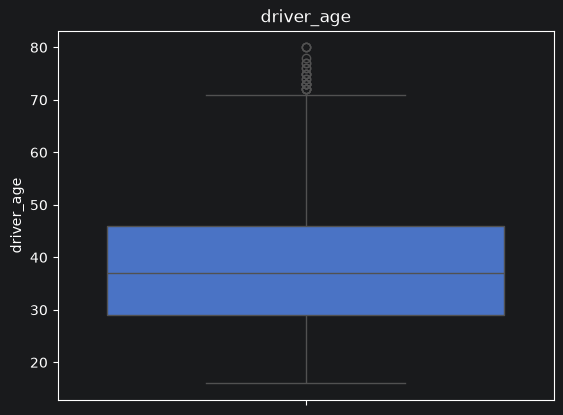

In [27]:

sns.boxplot(y=df['driver_age'])
plt.title('driver_age')

Text(0.5, 1.0, 'driver_experience_yrs')

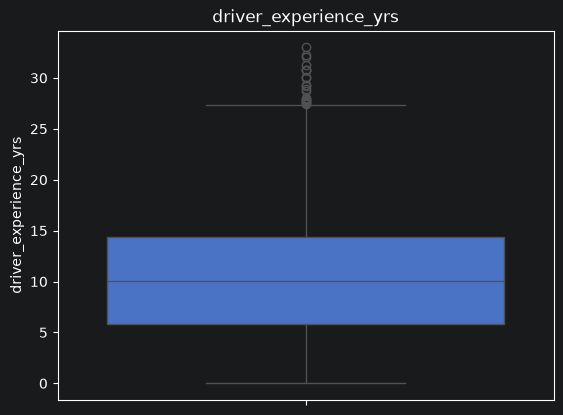

In [28]:

sns.boxplot(y=df['driver_experience_yrs'])
plt.title('driver_experience_yrs')

In [29]:
from scipy.stats import chi2_contingency
table=pd.crosstab(df['state'],df['accident_severity'])
chi2_score,p,dof,expected=chi2_contingency(table)
print("chi2 score: ",chi2_score)
print("p value: ",p)

chi2 score:  29.0724738488472
p value:  0.8506578092348178


In [30]:
df.drop(['state'],axis=1,inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_12504\2201112989.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['state'],axis=1,inplace=True)


In [31]:
from scipy.stats import chi2_contingency
table=pd.crosstab(df['junction_type'],df['accident_severity'])
chi2_score,p,dof,expected=chi2_contingency(table)
print("chi2 score: ",chi2_score)
print("p value: ",p)

chi2 score:  5.865627038719395
p value:  0.4384098941341701


In [32]:
df.drop(['accident_id','redundant_record_id','system_flag','random_noise_code','useless_ratio','time','hour','junction_type','speed_limit_kmh','date','num_casualties','num_vehicles'],axis=1,inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_12504\610231125.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['accident_id','redundant_record_id','system_flag','random_noise_code','useless_ratio','time','hour','junction_type','speed_limit_kmh','date','num_casualties','num_vehicles'],axis=1,inplace=True)


In [33]:
#weekend flag
df['is_weekend']=df['day_of_week'].apply(lambda x:1 if x in ['Saturday','Sunday'] else 0)

In [34]:
df.drop(['day_of_week'],axis=1,inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_12504\529228813.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['day_of_week'],axis=1,inplace=True)


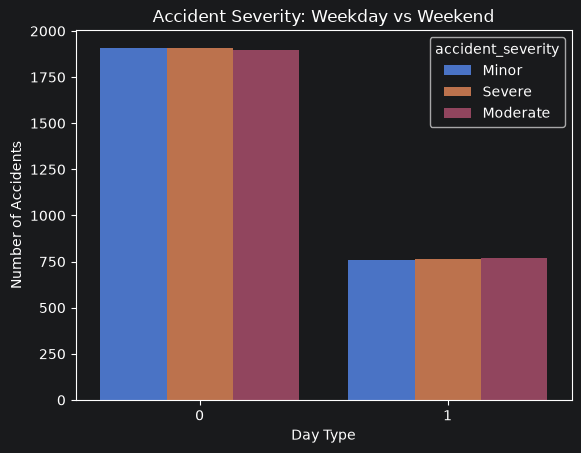

In [35]:
sns.countplot(data=df, x='is_weekend', hue='accident_severity')

plt.title('Accident Severity: Weekday vs Weekend')
plt.xlabel('Day Type')
plt.ylabel('Number of Accidents')
plt.show()

In [36]:
df.drop(['is_weekend'], axis=1, inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_12504\1353684879.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['is_weekend'], axis=1, inplace=True)


In [37]:
df.isna().sum()

road_type                  0
weather_condition        819
road_condition           824
light_condition          754
speed_kmh                805
visibility_m             812
driver_age               811
driver_experience_yrs    757
vehicle_type             811
alcohol_involved         801
seatbelt_worn            809
accident_severity          0
dtype: int64

In [38]:
#Handling missing values

In [39]:
df['weather_condition']=df['weather_condition'].fillna(df['weather_condition'].mode()[0])
df['road_condition']=df['road_condition'].fillna(df['road_condition'].mode()[0])
df['light_condition']=df['light_condition'].fillna(df['light_condition'].mode()[0])
df['speed_kmh']=df['speed_kmh'].fillna(df['speed_kmh'].median())
df['visibility_m']=df['visibility_m'].fillna(df['visibility_m'].median())
df['driver_age']=df['driver_age'].fillna(df['driver_age'].median())
df['driver_experience_yrs']=df['driver_experience_yrs'].fillna(df['driver_experience_yrs'].median())
df['vehicle_type']=df['vehicle_type'].fillna(df['vehicle_type'].mode()[0])
df['alcohol_involved']=df['alcohol_involved'].fillna(df['alcohol_involved'].mode()[0])
df['seatbelt_worn']=df['seatbelt_worn'].fillna(df['seatbelt_worn'].mode()[0])

In [40]:
df.isna().sum()

road_type                0
weather_condition        0
road_condition           0
light_condition          0
speed_kmh                0
visibility_m             0
driver_age               0
driver_experience_yrs    0
vehicle_type             0
alcohol_involved         0
seatbelt_worn            0
accident_severity        0
dtype: int64

In [41]:
#Encoding

In [42]:
dfe=pd.get_dummies(df[['road_type', 'weather_condition', 'road_condition', 'light_condition','vehicle_type']],drop_first=True,dtype=int)

In [43]:
df1=pd.concat([df,dfe],axis=1)

In [44]:
df1.drop(['road_type', 'weather_condition', 'road_condition', 'light_condition','vehicle_type'],axis=1,inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_12504\276632330.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df1.drop(['road_type', 'weather_condition', 'road_condition', 'light_condition','vehicle_type'],axis=1,inplace=True)


In [45]:
df1.head()

,speed_kmh,visibility_m,driver_age,driver_experience_yrs,alcohol_involved,seatbelt_worn,accident_severity,road_type_Highway,road_type_One-way,road_type_Rural Road,...,road_condition_Wet,light_condition_Daylight,light_condition_Dusk,light_condition_Night - Lit,light_condition_Night - Unlit,vehicle_type_Car,vehicle_type_Motorcycle,vehicle_type_SUV,vehicle_type_Truck,vehicle_type_Van
0,53.23,791.6,68.0,5.7,1.0,1.0,Minor,1,0,0,...,0,0,0,1,0,0,0,0,0,0
1,139.13,310.1,46.0,6.1,0.0,1.0,Severe,0,0,0,...,0,0,1,0,0,0,0,1,0,0
2,100.97,501.2,52.0,18.8,0.0,0.0,Severe,0,0,0,...,0,0,0,0,1,0,0,1,0,0
3,59.95,443.3,28.0,13.1,0.0,1.0,Moderate,0,0,0,...,1,1,0,0,0,0,1,0,0,0
4,53.25,882.9,39.0,15.1,0.0,1.0,Minor,0,0,0,...,1,1,0,0,0,1,0,0,0,0


In [46]:
#input-output seperation

In [47]:
x=df1.drop(['accident_severity'],axis=1).values
y = df1['accident_severity'].to_numpy(dtype=object)

In [48]:
print(x.shape)

(8000, 28)


In [49]:
print(y.shape)

(8000,)


In [50]:
#train test split

In [51]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30,stratify=y,random_state=42)


In [52]:
#Scaling

In [53]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
scaler.fit(x_train)
scaled_x_train=scaler.transform(x_train)
scaled_x_test=scaler.transform(x_test)

In [54]:
#ML

In [55]:
#KNN

In [56]:
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier(n_neighbors=9)
knn_model.fit(scaled_x_train,y_train)
y_pred1=knn_model.predict(scaled_x_test)

In [57]:
from sklearn.metrics import accuracy_score
score=accuracy_score(y_test,y_pred1)
score

0.6445833333333333

In [58]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred1)
cm

array([[633, 150,  17],
       [247, 448, 105],
       [ 94, 240, 466]])

In [59]:
#naive bayes

In [60]:
from sklearn.naive_bayes import MultinomialNB
nb_model=MultinomialNB()
nb_model.fit(scaled_x_train,y_train)
y_pred1=nb_model.predict(scaled_x_test)

In [61]:
from sklearn.metrics import accuracy_score
score=accuracy_score(y_test,y_pred1)
score

0.6208333333333333

In [62]:
#SVC

In [63]:
from sklearn.svm import SVC
svc_model=SVC()
svc_model.fit(scaled_x_train,y_train)
y_pred1=svc_model.predict(scaled_x_test)

In [64]:
from sklearn.metrics import accuracy_score
score=accuracy_score(y_test,y_pred1)
score

0.9216666666666666

In [65]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred1)
cm

array([[732,  68,   0],
       [ 28, 743,  29],
       [  0,  63, 737]])

In [66]:
#Decision Tree

In [67]:
from sklearn.tree import DecisionTreeClassifier
dtree=DecisionTreeClassifier(criterion='entropy')
dtree.fit(x_train,y_train)
y_pred1=dtree.predict(x_test)

In [68]:
from sklearn.metrics import accuracy_score
score=accuracy_score(y_test,y_pred1)
score

0.9395833333333333

In [69]:
#Random Forest

In [70]:
from sklearn.ensemble import RandomForestClassifier
rf_model=RandomForestClassifier(n_estimators=10)
rf_model.fit(x_train,y_train)
y_pred=rf_model.predict(x_test)

In [71]:
from sklearn.metrics import accuracy_score
score=accuracy_score(y_test,y_pred)
score

0.9429166666666666

In [72]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
cm

array([[757,  43,   0],
       [ 24, 743,  33],
       [  2,  35, 763]])

In [73]:
from sklearn.metrics import classification_report
report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

       Minor       0.97      0.95      0.96       800
    Moderate       0.90      0.93      0.92       800
      Severe       0.96      0.95      0.96       800

    accuracy                           0.94      2400
   macro avg       0.94      0.94      0.94      2400
weighted avg       0.94      0.94      0.94      2400



In [74]:
#pickle file

In [75]:
feature_columns = df1.drop(
    columns=['accident_severity']
).columns.tolist()

In [76]:
import pickle
import os

os.makedirs('models', exist_ok=True)

with open('models/rf_model.pkl', 'wb') as file:
    pickle.dump({
        'model': rf_model,
        'columns': feature_columns,
    }, file)
